In [1]:
%reload_ext autoreload
%autoreload 2

In [6]:
import torch

from topoflow.data.datasets import CrossDocked
from topoflow.data.dataloader import DataLoaderSampleable
from topoflow.utils.visualization import visualize_data

In [8]:
dataset = CrossDocked(root='../data/CrossDocked', split='train')

Processing...


Processed data will be saved to: ../data/CrossDocked/processed
Loading data split from: ../data/CrossDocked/raw/split_by_name.pt
Data split loaded successfully. Keys: ['train', 'test']

Processing 'train' split...


#failed: 1: 100%|██████████| 1000/1000 [00:16<00:00, 60.10it/s]


Processing train set took 0.28 minutes
Failed samples in train split: 1

Processing 'test' split...


#failed: 0: 100%|██████████| 100/100 [00:01<00:00, 50.46it/s]


...

#failed: 0: 100%|██████████| 300/300 [00:05<00:00, 51.00it/s]


Processing val set took 0.10 minutes
Failed samples in val split: 0

--- Summary of Failed Samples ---
Failed: PDB/SDF: RDM1_ARATH_7_163_0/2q3t_A_rec_2q3t_cps_lig_tt_docked_278_pocket10.pdb, RDM1_ARATH_7_163_0/2q3t_A_rec_2q3t_cps_lig_tt_docked_278.sdf - Reason: Processing returned None
Loading data from ../data/CrossDocked/processed/train.npz for split 'train'...
Normalizing coordinates for ligands and pockets in training split...
Original histogram: 911/61256 bins filled
Smoothed histogram: 15454/61256 bins filled
Reconstructing 999 samples from train.npz...


100%|██████████| 999/999 [00:00<00:00, 4694.69it/s]


Finished reconstructing samples for 'train'. Total samples for this split: 999
Collating 999 individual Data objects for split 'train'...
Saving collated data to ../data/CrossDocked/processed/train_crossdocked_pyg.pt...
Processed dataset saved successfully.
Loaded dataset from ../data/CrossDocked/processed/train_crossdocked_pyg.pt.


Done!


/home/marco/miniforge3/envs/topoflow/lib/python3.10/site-packages/torch_geometric/data/in_memory_dataset.py:300: UserWarning: It is not recommended to directly access the internal storage format `data` of an 'InMemoryDataset'. If you are absolutely certain what you are doing, access the internal storage via `InMemoryDataset._data` instead to suppress this warning. Alternatively, you can access stacked individual attributes of every graph via `dataset.{attr_name}`.
  warnings.warn(msg)


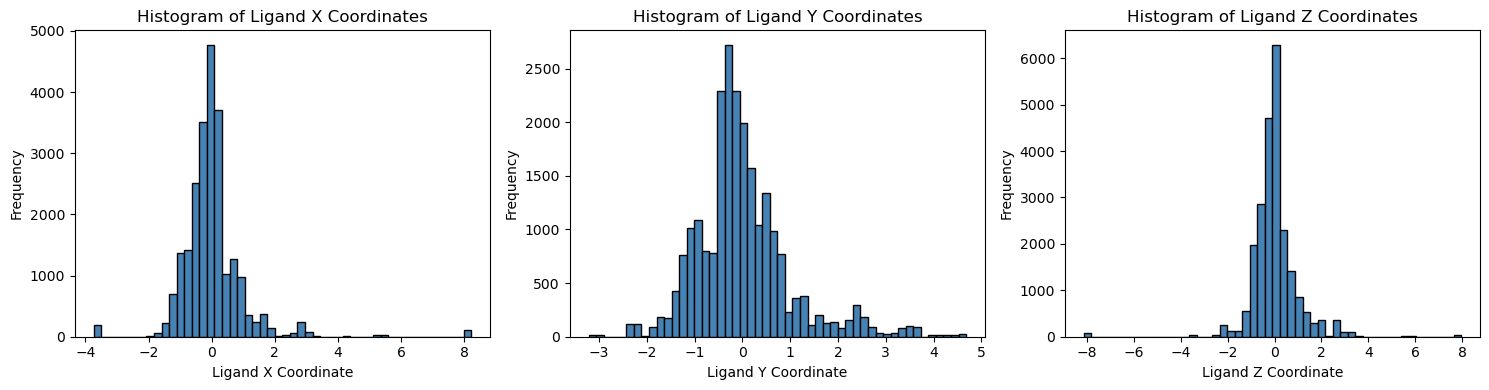

In [14]:
import matplotlib.pyplot as plt

# Get ligand coordinates as numpy array
data = dataset.data
x_lig = data.x_lig.cpu().numpy()  # shape: [num_atoms, 3]

# Set up side-by-side subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes = axes.flatten()
labels = ['X', 'Y', 'Z']

for i in range(3):
    axes[i].hist(x_lig[:, i], bins=50, color='steelblue', edgecolor='black')
    axes[i].set_xlabel(f'Ligand {labels[i]} Coordinate')
    axes[i].set_ylabel('Frequency')
    axes[i].set_title(f'Histogram of Ligand {labels[i]} Coordinates')

plt.tight_layout()
plt.show()


In [4]:
for data in dataset:
    print(data)
    break
print(len(dataset))

Data(h_lig=[26, 11], x_lig=[26, 3], batch_lig=[26], h_pocket=[389, 11], x_pocket=[389, 3], batch_pocket=[389])
999


In [19]:
print(dataset.data)
print(dataset.slices.keys())
print(dataset.slices['x_lig'].shape)
print(dataset.slices['h_lig'].shape)
print(dataset.slices['x_pocket'].shape)
print(dataset.slices['h_pocket'].shape)

Data(h_lig=[23426, 11], x_lig=[23426, 3], batch_lig=[23426], h_pocket=[362037, 11], x_pocket=[362037, 3], batch_pocket=[362037])
dict_keys(['h_lig', 'x_lig', 'batch_lig', 'h_pocket', 'x_pocket', 'batch_pocket'])
torch.Size([1000])
torch.Size([1000])
torch.Size([1000])
torch.Size([1000])


In [38]:
image_path = "outputs/data_0.png"
session_path = "outputs/session_0.pse"
visualize_data(data, image_path=image_path, session_path=session_path, dataset_name='crossdock_full')

Successfully saved ligand to: temp_ligand.sdf
Successfully saved pocket to: temp_pocket.pdb
Loading protein from: temp_pocket.pdb as 'protein'
Loading ligand from: temp_ligand.sdf as 'ligand'
Applying custom ligand coloring based on dataset_param...
Image saved to: outputs/data_0.png
Session saved to: outputs/session_0.pse

PyMOL visualization setup complete. You can now interact with the window.


In [40]:
sampleable_dataloader = DataLoaderSampleable(dataset, batch_size=100, shuffle=True, num_workers=4)
print(len(sampleable_dataloader))

/home/marco/miniforge3/envs/topoflow/lib/python3.10/site-packages/torch_geometric/deprecation.py:26: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  warnings.warn(out)


10


In [44]:
batch = sampleable_dataloader.sample()
print(batch)
print(torch.max(batch.batch_lig))

DataBatch(h_lig=[2307, 11], x_lig=[2307, 3], batch_lig=[2307], h_pocket=[33990, 11], x_pocket=[33990, 3], batch_pocket=[33990])
tensor(99)
